In [ ]:
from qiskit import QuantumCircuit
from qiskit.circuit.library import MCMTGate, ZGate

def grover_oracle(marked_states, num_ancillas):
    if not isinstance(marked_states, list):
        marked_states = [marked_states]
    
    num_qubits = len(marked_states[0])
    
    # CRITICAL: Include the ancilla qubits in this circuit container
    qc = QuantumCircuit(num_qubits + num_ancillas)
    
    for target in marked_states:
        rev_target = target[::-1]
        zero_inds = [ind for ind in range(num_qubits) if rev_target.startswith("0", ind)]
        
        if zero_inds:
            qc.x(zero_inds)
            
        # Apply the multi-controlled Z gate only to the 7 data qubits
        # Qiskit indices 0 to 6 are data, 7 to 11 will be left completely idle here
        data_qubits = list(range(num_qubits))
        qc.compose(MCMTGate(ZGate(), num_qubits - 1, 1), qubits=data_qubits, inplace=True)
        
        if zero_inds:
            qc.x(zero_inds)
            
    return qc

In [13]:
from qiskit.circuit.library import grover_operator

marked_states=["1101001"]

num_ancillas=5

# 1. Build the ancilla-inclusive oracle
oracle = grover_oracle(marked_states=marked_states, num_ancillas=num_ancillas)

# 2. Build the Grover Operator, restricting the diffuser reflection to just the 7 data qubits
grover_op = grover_operator(oracle)

In [20]:
# Theoretical optimal number of Grover iterations
import math

N = 2 ** (grover_op.num_qubits - num_ancillas)
M = len(marked_states)

optimal_num_iterations = math.floor(
    math.pi / (4 * math.asin(math.sqrt(M / N)))
)

print("Theoretical optimal iterations:", optimal_num_iterations)

Theoretical optimal iterations: 8


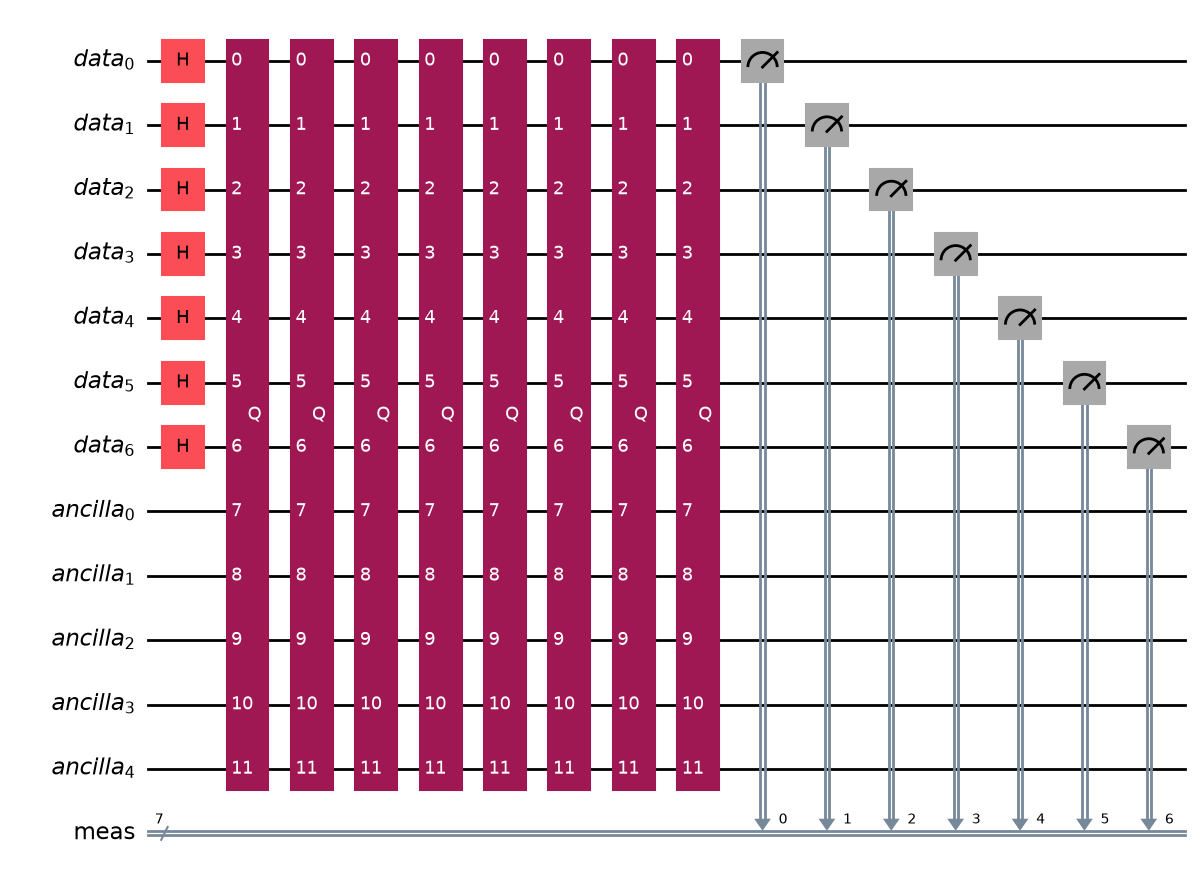

In [21]:
from qiskit import QuantumRegister, ClassicalRegister, QuantumCircuit
from qiskit.circuit.library import MCXGate

qr_data = QuantumRegister(7, name='data')
qr_target = QuantumRegister(1, name='target')
# For a 7-control MCX v-chain, you need (num_controls - 2) ancillas -> 5 ancillas
qr_ancilla = QuantumRegister(5, name='ancilla')
cr = ClassicalRegister(7, name='meas')

mcx_gate = MCXGate(num_ctrl_qubits=7) 

import math
from qiskit import QuantumRegister, ClassicalRegister, QuantumCircuit
from qiskit.circuit.library import grover_operator

marked_states = ["1101001"]
num_ancillas = 5

# 1. Build the 12-qubit ancilla-inclusive oracle
oracle = grover_oracle(marked_states=marked_states, num_ancillas=num_ancillas)

# 2. FIX: Explicitly restrict the reflection diffuser to just the 7 data qubits (indices 0 to 6)
# This prevents the operator from scrambling or ignoring your ancillas!
grover_op = grover_operator(oracle)

# 3. Setup your main circuit container (Exactly matching your oracle's 12-qubit width)
qr_data = QuantumRegister(7, name='data')
qr_ancilla = QuantumRegister(5, name='ancilla')
cr = ClassicalRegister(7, name='meas')

qc = QuantumCircuit(qr_data, qr_ancilla, cr)

# 4. Initialize your 7 active data qubits to the |+> state
qc.h(qr_data)


qc.compose(grover_op.power(optimal_num_iterations), inplace=True)

# 6. Measure ONLY the 7 active data qubits
qc.measure(qr_data, cr)

# qc.draw(output="mpl", style="iqp")

qc.draw(output="mpl", style="iqp")

In [22]:
from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService()

backend = service.backend(name="ibm_fez")

In [23]:
from qiskit import generate_preset_pass_manager
from qiskit_ibm_runtime import SamplerV2 as Sampler

shots = 10_000


pm = generate_preset_pass_manager(optimization_level=3, backend=backend)

isa_circuit = pm.run(qc)

sampler = Sampler(mode=backend)

sampler.options.dynamical_decoupling.enable = True
sampler.options.dynamical_decoupling.sequence_type = "XpXm" 

# Careful here: you're using compute minutes

In [24]:
job = sampler.run([isa_circuit])

In [25]:
result = job.result()
dist = result[0].data.meas.get_counts()

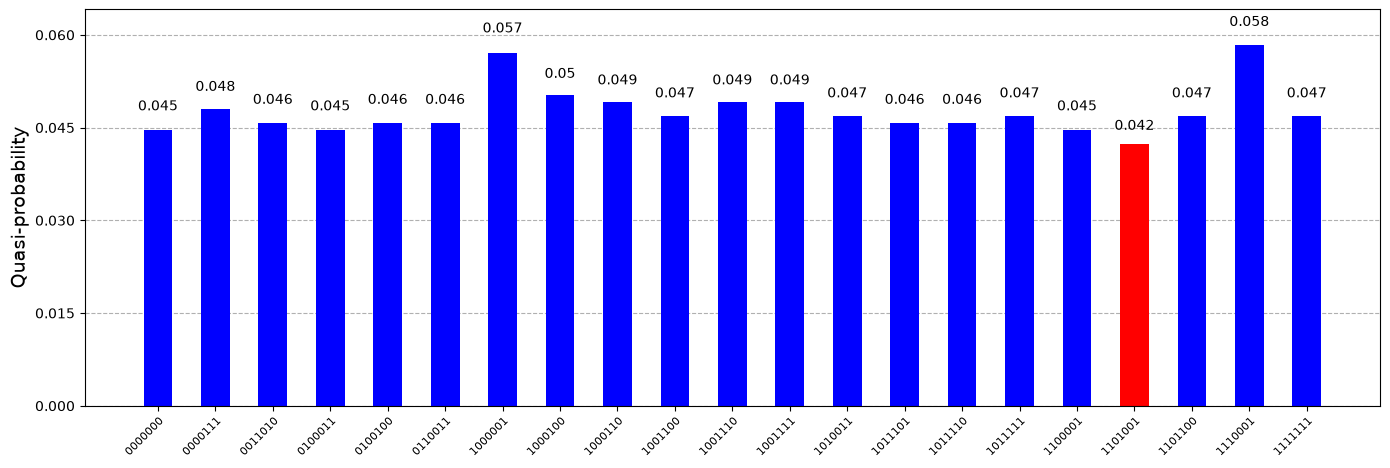

<Figure size 640x480 with 0 Axes>

In [26]:
import matplotlib.pyplot as plt
from qiskit.visualization import plot_distribution

# %matplotlib inline

# Bitstrings that must appear in red
red_states = marked_states

# Get the 20 most frequent outcomes
top_20 = dict(sorted(dist.items(), key=lambda item: item[1], reverse=True)[:20])

# Force all red states into the selection
for state in red_states:
    if state in dist:
        top_20[state] = dist[state]

# Plot the selected outcomes
fig = plot_distribution(top_20, figsize=(14, 5), color='blue')

# Color the specified states red
ax = fig.axes[0]
for bar, label in zip(ax.patches, [tick.get_text() for tick in ax.get_xticklabels()]):
    if label in red_states:
        bar.set_facecolor('red')

ax.tick_params(axis='x', labelrotation=45, labelsize=8)
plt.tight_layout()
display(fig)
plt.close(fig)

In [27]:
from pathlib import Path

output_dir = Path("figures")
output_dir.mkdir(parents=True, exist_ok=True)

# Plot the selected outcomes
fig = plot_distribution(dist, figsize=(200, 5), color='blue')

# Color the specified states red
ax = fig.axes[0]
for bar, label in zip(ax.patches, [tick.get_text() for tick in ax.get_xticklabels()]):
    if label in marked_states:
        bar.set_facecolor('red')

fig.savefig(output_dir / "dist_2.png", dpi=300, bbox_inches="tight")